# Relationships between numeric variables

This notebook is the third lecture of block 1. It moves from describing one variable to relationships between two numeric variables. We recap the scatter plot and two correlation coefficients (Pearson and Spearman), then look at **confounding**: a third variable that creates, hides or reverses a relationship, with Simpson's paradox as the extreme case. The least-squares line through a scatter plot, the bridge to regression in Session 6, follows in block 2 ([06-lecture-testing-and-communicating.ipynb](06-lecture-testing-and-communicating.ipynb)).

```mermaid
flowchart LR
    S["scatter plot"] --> C["correlation<br/>Pearson r, Spearman rho"]
    C --> Z{"third variable<br/>behind it?"}
    Z -->|"check subgroups,<br/>adjust"| A["compare within groups"]
    Z -->|"no"| R["regression line<br/>(block 2)"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## Scatter plots

### Concept

A **scatter plot** places one point per observation at (x, y). Read it for four things: **direction** (up, down, none), **form** (straight, curved, clusters), **strength** (how tightly points follow the form) and **unusual points** (outliers, points with extreme x).

With many observations, points overlap (**overplotting**) and the plot shows only the outline of the data. Remedies: transparency (`alpha`), a random subsample, small jitter for integer values, a 2D histogram or hexbin plot, and binned means.

### Why it matters

A correlation coefficient summarises a scatter plot in one number. Without looking at the plot you cannot tell whether that number describes a straight-line relationship, a curve or two outliers.

### How it works in Python

{2: 2599, 4: 1352, 3: 706}


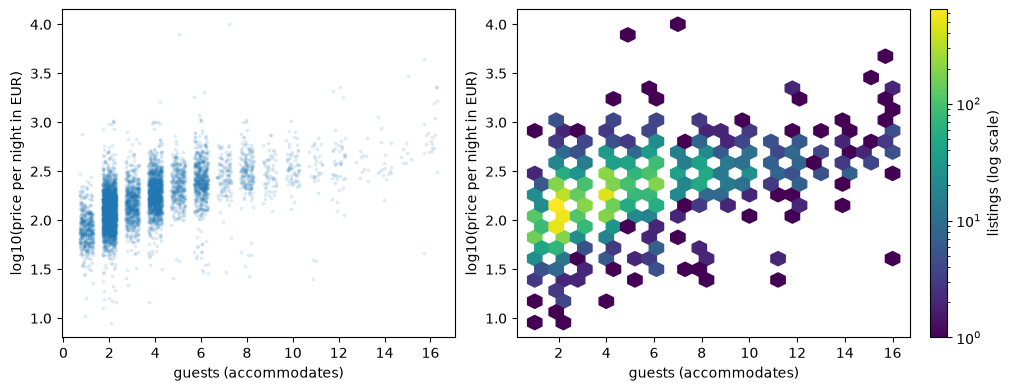

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]   # comparable prices
x = short["accommodates"]                                # number of guests: a small count
y = np.log10(short["price"])                             # log10 of the price: price is right-skewed
rng = np.random.default_rng(0)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
left.scatter(x + rng.uniform(-0.3, 0.3, len(x)), y, s=3, alpha=0.1)   # jitter + transparency
hb = right.hexbin(x, y, gridsize=25, bins="log", cmap="viridis")      # counts per hexagon
fig.colorbar(hb, ax=right, label="listings (log scale)")
for ax in (left, right):
    ax.set(xlabel="guests (accommodates)", ylabel="log10(price per night in EUR)")
print(x.value_counts().head(3).to_dict())   # {2: 2599, 4: 1352, 3: 706}: integer values overlap

### In practice

- Gapminder's bubble charts of income against life expectancy (Hans Rosling) made the scatter plot a standard tool of public communication.
- Quality engineering plots process settings against defect rates to find operating windows.
- Real-estate analysts plot price against floor area before fitting any model; the same holds for nightly prices against the number of guests.

> **Tip.** Put the variable you think of as the "cause" or predictor on the x-axis and the outcome on the y-axis. It does not prove anything, but it matches how readers read the plot and how regression is written.

## Pearson and Spearman correlation

### Concept

- **Pearson's r** measures how closely points follow a **straight line**, from −1 through 0 to +1. **r²** is the share of the variance of y that a straight line explains.
- **Spearman's ρ** (rho) is Pearson's r computed on the **ranks**. It captures any **monotonic** relationship (always up or always down, not necessarily straight) and resists outliers.

Worked example: for the points (1, 1), (2, 3), (3, 2), (4, 100), Pearson's r is about 0.78, driven by the last point. The ranks of y are 1, 3, 2, 4, and Spearman's ρ = 0.8. Change 100 to 1,000 and Pearson moves to 0.77 while Spearman stays at 0.8, because the ranks do not change.

r is not the slope. r = 0.9 can mean that y rises by 1 cent or by 1,000 euros per unit of x; the slope is regression's job. r also misses curves: a perfect U-shape has r ≈ 0.

### Why it matters

Correlation is the first screen for variables that move together: candidate features, KPI drivers worth investigating, redundant predictors. Choosing the wrong coefficient can make a clear relationship look weak.

### How it works in Python

In [3]:
import numpy as np
import pandas as pd
from scipy import stats

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]
guests, price = short["accommodates"], short["price"]

print(round(stats.pearsonr(guests, price).statistic, 3))     # 0.408
print(round(stats.spearmanr(guests, price).statistic, 3))    # 0.642
res = stats.pearsonr(guests, np.log(price))
ci = res.confidence_interval()
print(round(res.statistic, 3), round(ci.low, 3), round(ci.high, 3))   # 0.594 0.579 0.61

# Is Pearson driven by a few points? Drop the 5 most expensive listings (up to 10,025 EUR)
keep = ~price.index.isin(price.nlargest(5).index)
print(round(stats.pearsonr(guests[keep], price[keep]).statistic, 3))   # 0.573: five points out of 6,701

# rating and price: no monotonic relationship
rated = short.dropna(subset=["review_scores_rating"])
print(round(stats.spearmanr(rated["review_scores_rating"], rated["price"]).statistic, 3))                           # 0.036
print(round(stats.spearmanr(rated["review_scores_rating"], rated["price"] / rated["accommodates"]).statistic, 3))   # 0.175

0.408
0.642
0.594 0.579 0.61
0.573
0.036
0.175


The three coefficients tell different stories about the same scatter plot. Pearson's r on raw prices is 0.41; Spearman's ρ is 0.64; Pearson on the log price is 0.59. The gap is the worked example in real data: five listings with prices in the thousands (out of 6,701) hold down Pearson's r on the raw scale, and removing them raises it from 0.41 to 0.57. Spearman and the log scale are not fooled by them. Larger listings clearly cost more, and the relationship is strong. Ratings, by contrast, are unrelated to the nightly price (ρ = 0.04), and only weakly related to the price per guest (ρ = 0.18): guests rate value for money, not price.

### In practice

- Finance computes correlation matrices of asset returns for portfolio construction; analysts use rank correlation when returns have heavy tails.
- Psychometrics reports the correlation between two administrations of a test as its test–retest reliability.
- Marketing analysts correlate advertising spend with sales, where both follow the season (see confounding below).

> **Caution.** **Correlation is not causation.** Larger listings may cost more because hosts charge per guest, because large flats are in expensive central buildings, or because entire homes are both larger and pricier than rooms. The correlation alone cannot tell these apart; adding one guest's bed to a flat does not raise its market price by the slope of the line.

> 📖 **Read more:** [extras/09-correlation.ipynb](extras/09-correlation.ipynb) (Think Stats, chapter 7): scatter plots with jitter and transparency, decile plots, Pearson's and Spearman's correlation and their weaknesses, worked through on survey data.

## Confounding and Simpson's paradox

### Concept

A **confounder** is a third variable that is related to both variables of interest and creates or distorts the relationship between them. **Simpson's paradox** is the extreme case: a relationship in the pooled data vanishes or reverses inside every (or most) subgroups.

The classic real case is the 1973 graduate admissions at UC Berkeley (Bickel, Hammel & O'Connell, 1975). Pooled over the six largest departments, 45 % of men and 30 % of women were admitted. Department by department, women were admitted at a higher rate in four of six. Women had applied more often to the departments that rejected most applicants. The department was the confounder.

![Left: Berkeley admission rates by department for men and women. Right: mean nightly price in Friedrichshain-Kreuzberg and Charlottenburg-Wilmersdorf for short stays, medium-term listings and all listings](../figures/simpsons-paradox.png)

The listings contain a real, milder version. Among all listings with a price, Friedrichshain-Kreuzberg is €10 more expensive than Charlottenburg-Wilmersdorf on average (€158.5 against €148.5). Within each type of stay the gap disappears: short stays cost €188.6 and €190.1, medium-term listings €32.2 and €32.3, both slightly *higher* in Charlottenburg-Wilmersdorf. The pooled gap comes entirely from the mix: 26 % of the priced listings in Charlottenburg-Wilmersdorf are medium-term offers with their low price field, against 19 % in Friedrichshain-Kreuzberg. Strictly, this is a reversal, but within the groups the differences (€0.1 and €1.5) are far too small to matter; the honest summary is "the gap vanishes", not "the order reverses". We searched all district pairs for a reversal that is large and robust and found none; we report what we found.

The type of stay is not the only confounder. Among short-stay listings, Neukölln is 28 % cheaper than Mitte in a regression of log price on district alone, and 20 % cheaper once room type and number of guests are held fixed: about a third of the raw gap reflects that Neukölln has more private rooms and smaller listings.

### Why it matters

Before acting on any relationship, ask: what else differs between these groups? This question is the reason randomised experiments exist (A/B tests in block 2, [06-lecture-testing-and-communicating.ipynb](06-lecture-testing-and-communicating.ipynb)) and the reason regression adds control variables (Session 6).

### How it works in Python

In [4]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
priced = listings[listings["price"].notna()].copy()
priced["stay"] = np.where(priced["minimum_nights"].ge(28), "medium-term", "short")
pair = priced[priced["district"].isin(["Friedrichshain-Kreuzberg", "Charlottenburg-Wilm."])]

print(pair.groupby("district")["price"].mean().round(1).to_dict())
# {'Charlottenburg-Wilm.': 148.5, 'Friedrichshain-Kreuzberg': 158.5}   <- pooled: a 10 EUR gap
print(pair.groupby(["district", "stay"])["price"].mean().unstack().round(1))
# stay                      medium-term  short
# district
# Charlottenburg-Wilm.             32.3  190.1
# Friedrichshain-Kreuzberg         32.2  188.6                         <- within each stay type: no gap
print(pair.groupby("district")["stay"].apply(lambda s: (s == "medium-term").mean()).round(2).to_dict())
# {'Charlottenburg-Wilm.': 0.26, 'Friedrichshain-Kreuzberg': 0.19}     <- the mix differs

short = priced[priced["stay"] == "short"].assign(log_price=lambda d: np.log(d["price"]))
raw = smf.ols('log_price ~ C(district, Treatment("Mitte"))', data=short).fit()
adjusted = smf.ols('log_price ~ C(district, Treatment("Mitte")) + C(room_type) + accommodates', data=short).fit()
name = 'C(district, Treatment("Mitte"))[T.Neukölln]'
print(round(np.exp(raw.params[name]) - 1, 3), round(np.exp(adjusted.params[name]) - 1, 3))   # -0.282 -0.195

{'Charlottenburg-Wilm.': 148.5, 'Friedrichshain-Kreuzberg': 158.5}
stay                      medium-term  short
district                                    
Charlottenburg-Wilm.             32.3  190.1
Friedrichshain-Kreuzberg         32.2  188.6
{'Charlottenburg-Wilm.': 0.26, 'Friedrichshain-Kreuzberg': 0.19}
-0.282 -0.195


The pooled district comparison mixes two things: the price of comparable listings and the composition of each district's offer. Neither "28 % cheaper" nor "20 % cheaper" is "the" effect of the district; the second answers a different question ("for a listing of the same type and size"). Size and room type may not be the only differences: location within the district, flat quality and the share of professional hosts also vary, and the data cannot rule out further confounders.

### In practice

- Hospital league tables: a specialist hospital that treats sicker patients can have a higher raw mortality rate than a general hospital and still be better for every type of patient; risk adjustment addresses this.
- Kidney-stone treatment (Charig et al., 1986): treatment A had higher success rates for both small and large stones, but treatment B looked better pooled, because A was used more often for the harder large stones.
- Marketing attribution: a channel looks best in aggregate only because it runs in the strongest market.

> **Warning.** Adjusting for a variable is not always right. Adjusting for a variable that is itself caused by the treatment (a **mediator** or a **collider**) can create bias. Draw the causal story before deciding what to control for.

## Check your understanding

1. Pearson's r between guests and price rises from 0.41 to 0.57 when the five most expensive listings are dropped, while Spearman's ρ is 0.64 either way. Why?
2. Name two variables other than room type and size that could confound the price difference between Mitte and Neukölln.
3. In the Berkeley case, what was the confounder and how did it produce the pooled gap?

## Further reading

- Downey, A. B. (2025). *Think Stats* (3rd ed.), chapter 7 "Relationships between variables". <https://allendowney.github.io/ThinkStats/chap07.html>
- Bickel, P. J., Hammel, E. A., & O'Connell, J. W. (1975). Sex bias in graduate admissions: Data from Berkeley. *Science*, 187(4175), 398–404. <https://doi.org/10.1126/science.187.4175.398>
- Pearl, J., Glymour, M., & Jewell, N. P. (2016). *Causal Inference in Statistics: A Primer*, chapter 1 (Simpson's paradox). Wiley.